# Early Warning System para evasão em cursos técnicos da Rede Federal

Trabalho de Conclusão de Curso de Tecnologia em Sistemas para Internet (Colégio Politécnico/UFSM).

Este notebook mostra, passo a passo, como o modelo do protótipo foi construído:

1. carrega os **Microdados de Eficiência Acadêmica** da Plataforma Nilo Peçanha (PNP), ano-base 2025;
2. define a população (matrículas de **cursos técnicos** que já concluíram ou evadiram);
3. prepara **21 atributos** do estudante, do curso e da instituição;
4. separa as turmas em treino, validação e teste;
5. treina um classificador **CatBoost** e o compara com referências simples;
6. avalia o uso pretendido: **ordenar os estudantes dentro de uma mesma unidade de ensino**;
7. explica os escores com **SHAP** e define níveis de alerta;
8. exporta o modelo e as bases de demonstração usadas pelo protótipo.

**Como ler os resultados**
- O **escore do modelo** ordena as matrículas da mais para a menos parecida com casos de evasão. Ele não é uma
  probabilidade calibrada.
- A avaliação é **retrospectiva**: usa desfechos que já aconteceram.
- Os valores SHAP mostram **como o modelo chegou ao escore**, não as causas da evasão.

**Como executar:** no Google Colab, *Ambiente de execução → Executar tudo* (CPU padrão, cerca de 10 minutos).
Localmente, abra o notebook na raiz do projeto. As saídas ficam na pasta `resultados/`.

## 1. Configuração

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('catboost') is None:          # o Colab não traz o CatBoost instalado
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'catboost==1.2.10'])

In [2]:
import hashlib
import json
import platform
import urllib.request
from pathlib import Path

import catboost
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from catboost import CatBoostClassifier, Pool
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMENTE = 42
LIMIAR = 0.50                                  # usado nas métricas que dependem de um ponto de corte
NIVEIS_ALERTA = {'medio': 0.30, 'alto': 0.70}  # níveis experimentais exibidos no protótipo
PARAMETROS_CATBOOST = {
    'iterations': 800, 'learning_rate': 0.05, 'depth': 6,
    'loss_function': 'Logloss', 'auto_class_weights': 'Balanced',
    'random_seed': SEMENTE,
    'thread_count': 4,   # o resultado do CatBoost varia levemente com o nº de threads; fixar garante a reprodução
}

ARQUIVO_DADOS = Path('dados/microdados_eficiencia_academica_2025.csv.gz')
URL_DADOS = ('https://d236w85zd3t8iw.cloudfront.net/pnp-tests/microdados/2025/'
             'microdados_eficiencia_academica_2025.csv.gz')
SHA256_DADOS = '18e9ad28b486c4793ce41f92e7b113c8a931aff522673707614db35687f00bed'

SAIDA = Path('resultados')
for pasta in ('figuras', 'tabelas', 'prototipo'):
    (SAIDA / pasta).mkdir(parents=True, exist_ok=True)

AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#8a8a85'
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 160)


def salvar_figura(fig, nome):
    fig.savefig(SAIDA / 'figuras' / nome, dpi=200, bbox_inches='tight')
    plt.show()


def salvar_tabela(tabela, nome):
    tabela.to_csv(SAIDA / 'tabelas' / nome, encoding='utf-8-sig')


print('Python', platform.python_version(), '| catboost', catboost.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__)

Python 3.14.10 | catboost 1.2.10 | pandas 3.1.1 | scikit-learn 1.9.1


## 2. Dados

Microdados públicos de Eficiência Acadêmica da PNP, **ano-base 2025**: cada linha é uma matrícula, sem nome nem
CPF, de ciclos com término previsto até 2024. O arquivo é lido de `dados/` ou baixado da fonte, e o SHA-256 confirma
que é o mesmo usado no trabalho.

In [3]:
def sha256(caminho):
    resumo = hashlib.sha256()
    with open(caminho, 'rb') as arquivo:
        for bloco in iter(lambda: arquivo.read(1 << 20), b''):
            resumo.update(bloco)
    return resumo.hexdigest()


if not ARQUIVO_DADOS.exists():
    ARQUIVO_DADOS.parent.mkdir(exist_ok=True)
    print('Baixando', URL_DADOS)
    urllib.request.urlretrieve(URL_DADOS, ARQUIVO_DADOS)
assert sha256(ARQUIVO_DADOS) == SHA256_DADOS, 'o arquivo de dados difere do usado no trabalho'

base = pd.read_csv(ARQUIVO_DADOS, sep=';', compression='gzip', low_memory=False)
print(f'{len(base):,} matrículas e {base.shape[1]} colunas'.replace(',', '.'))

1.290.968 matrículas e 79 colunas


## 3. População e desfecho

A coluna `Categoria da Situação` agrupa as matrículas em *Concluintes*, *Evadidos* e *Em curso*. O estudo se
restringe aos **cursos técnicos**: os cursos de qualificação profissional (FIC) são a maioria da base, mas são curtos
e têm um perfil de evasão muito diferente.

In [4]:
com_desfecho = base[base['Categoria da Situação'].isin(['Concluintes', 'Evadidos'])]
por_tipo = (com_desfecho.assign(evadido=com_desfecho['Categoria da Situação'].eq('Evadidos'))
            .groupby('Tipo de Curso')['evadido']
            .agg(matriculas='size', evasao_pct=lambda s: round(100 * s.mean(), 1))
            .sort_values('matriculas', ascending=False))
salvar_tabela(por_tipo, 'desfecho_por_tipo_de_curso.csv')
por_tipo

,matriculas,evasao_pct
Tipo de Curso,,
Qualificação Profissional (FIC),1030495,16.1
Técnico,146345,46.3
Especialização (Lato Sensu),21018,43.8
Tecnologia,18505,75.5
Bacharelado,15445,66.1
Licenciatura,13801,73.9
Especialização Técnica,11662,20.8
Mestrado Profissional,1979,26.4
Ensino Médio,1751,23.4


**Desfecho (variável-alvo):** `Evadido = 1` para *Evadidos* e `0` para *Concluintes*. As matrículas *Em curso*
ainda não têm desfecho e ficam de fora.

In [5]:
tecnicos = base[base['Tipo de Curso'].eq('Técnico')]
dados = tecnicos[tecnicos['Categoria da Situação'].isin(['Concluintes', 'Evadidos'])].reset_index(drop=True)
y = dados['Categoria da Situação'].eq('Evadidos').astype(int)
turmas = dados['Código do Ciclo Matricula'].astype(str)    # ciclo de matrícula = turma

volumes = pd.DataFrame({
    'Cursos técnicos': tecnicos['Categoria da Situação'].value_counts(),
    'População do estudo': dados['Categoria da Situação'].value_counts(),
}).fillna(0).astype(int)
volumes.loc['Total'] = volumes.sum()
salvar_tabela(volumes, 'volumes_populacao.csv')
print(f'População: {len(dados):,} matrículas em {turmas.nunique():,} turmas'.replace(',', '.'),
      f'| evadidos: {100 * y.mean():.1f}%'.replace('.', ','))
volumes

População: 146.345 matrículas em 4.118 turmas | evadidos: 46,3%


,Cursos técnicos,População do estudo
Categoria da Situação,,
Concluintes,78597,78597
Em curso,9850,0
Evadidos,67748,67748
Total,156195,146345


## 4. Atributos

Os atributos são informações que **existem no momento do ingresso** do estudante e que estão preenchidas da mesma
forma para quem concluiu e para quem evadiu. São 21 atributos, em três grupos:

| Grupo | Atributos |
|---|---|
| Estudante | idade no ingresso, sexo, tipo de deficiência |
| Curso e oferta | eixo e subeixo tecnológico, curso, tipo de oferta, modalidade, turno, fonte de financiamento, programa associado, carga horária, carga horária mínima, fator de esforço, inscritos, vagas ofertadas, vagas de ampla concorrência, duração prevista do ciclo |
| Instituição | instituição, unidade de ensino, UF |

Ficam de fora: cinco campos do estudante preenchidos de forma desigual (seção 4.3), o desfecho e suas datas,
identificadores (códigos de matrícula, ciclo, unidade e município), colunas
constantes nos técnicos (`Tipo de Curso`, `Formação de Professores`), colunas que repetem a unidade (`Município`,
`Região`), colunas sempre vazias (`Habilitação`, `Código do Curso - eMEC`), a idade e a faixa etária brutas
(substituídas pela idade no ingresso) e as vagas extraordinárias e por cota (quase sempre vazias).

In [6]:
ATRIBUTOS_ESTUDANTE = ['Sexo', 'Tipo de Deficiencia']
ATRIBUTOS_CURSO = ['Eixo Tecnológico', 'Subeixo Tecnológico', 'Nome de Curso', 'Tipo de Oferta',
                   'Modalidade de Ensino', 'Turno', 'Fonte de Financiamento', 'Programa Associado']
ATRIBUTOS_INSTITUICAO = ['Instituição', 'Unidade de Ensino', 'UF']
CATEGORICAS = ATRIBUTOS_ESTUDANTE + ATRIBUTOS_CURSO + ATRIBUTOS_INSTITUICAO
NUMERICAS = ['Idade_Inicio_Estimada', 'Carga Horaria', 'Carga Horaria Mínima', 'Fator Esforço Curso',
             'Total de Inscritos', 'Vagas Ofertadas', 'Vagas Regulares AC', 'Duracao_Ciclo_Dias']
ATRIBUTOS = CATEGORICAS + NUMERICAS
REFERENCIA_IDADE = pd.Timestamp('2025-12-31')   # data em que a coluna Idade é medida (ver 4.1)


def preparar_atributos(registros):
    # Monta a tabela de atributos do modelo a partir das colunas originais dos microdados.
    inicio = pd.to_datetime(registros['Data de Inicio do Ciclo'], dayfirst=True, errors='coerce')
    fim = pd.to_datetime(registros['Data de Fim Previsto do Ciclo'], dayfirst=True, errors='coerce')
    idade = pd.to_numeric(registros['Idade'], errors='coerce').where(lambda i: i.between(5, 100))
    X = pd.DataFrame(index=registros.index)
    for coluna in CATEGORICAS:
        X[coluna] = registros[coluna].fillna('Desconhecido').astype(str)
    for coluna in NUMERICAS:
        if coluna == 'Idade_Inicio_Estimada':
            X[coluna] = (idade - (REFERENCIA_IDADE - inicio).dt.days / 365.25).round(1)
        elif coluna == 'Duracao_Ciclo_Dias':
            X[coluna] = (fim - inicio).dt.days.astype(float)
        else:                                      # alguns números vêm com vírgula decimal
            texto = registros[coluna].astype(str).str.replace(',', '.', regex=False)
            X[coluna] = pd.to_numeric(texto, errors='coerce')
    return X.reset_index(drop=True)


X = preparar_atributos(dados)
print(f'{X.shape[1]} atributos: {len(CATEGORICAS)} categóricos e {len(NUMERICAS)} numéricos')
X[NUMERICAS].describe().T[['count', 'mean', 'min', '50%', 'max']].round(1)

21 atributos: 13 categóricos e 8 numéricos


,count,mean,min,50%,max
Idade_Inicio_Estimada,146343.0,22.7,0.2,18.1,86.6
Carga Horaria,146345.0,2338.3,40.0,1710.0,5545.0
Carga Horaria Mínima,146345.0,1075.8,800.0,1200.0,2000.0
Fator Esforço Curso,146345.0,1.1,1.0,1.0,1.5
Total de Inscritos,145281.0,352.8,0.0,121.0,9913.0
Vagas Ofertadas,145281.0,155.4,1.0,40.0,3349.0
Vagas Regulares AC,145158.0,127.4,1.0,20.0,3349.0
Duracao_Ciclo_Dias,146345.0,846.9,34.0,823.0,1827.0


### 4.1 Idade no ingresso

A coluna `Idade` não é a idade no ingresso: ela é medida em uma data fixa do ano-base. A tabela mostra isso nos
cursos integrados, que recebem estudantes de idade parecida: a mediana da idade cai um ano a cada ano a mais de início
do ciclo. Por isso a idade no ingresso é **estimada**: `Idade` menos o tempo entre o início do ciclo e 31/12/2025.
Como a idade vem em anos inteiros, a estimativa tem incerteza de até cerca de dois anos.

In [7]:
integrado = dados['Tipo de Oferta'].eq('Integrado')
ano_inicio = pd.to_datetime(dados['Data de Inicio do Ciclo'], dayfirst=True, errors='coerce').dt.year
pd.DataFrame({
    'idade (coluna original)': pd.to_numeric(dados['Idade'], errors='coerce')[integrado].groupby(ano_inicio).median(),
    'idade no ingresso (estimada)': X['Idade_Inicio_Estimada'][integrado].groupby(ano_inicio).median(),
    'matrículas': integrado.groupby(ano_inicio).sum(),
}).rename_axis('ano de início do ciclo').round(1)

,idade (coluna original),idade no ingresso (estimada),matrículas
ano de início do ciclo,,,
2019,22.0,15.2,69
2020,21.0,15.2,2588
2021,20.0,15.4,28009
2022,19.0,15.2,35799
2023,18.0,15.7,64
2024,17.0,15.1,6


### 4.2 Valores ausentes

O gráfico mostra todas as colunas com valores ausentes na população e se cada uma entrou no modelo. Nos atributos
categóricos, a ausência vira a categoria `Desconhecido`; nos numéricos, o CatBoost trata o valor ausente diretamente.

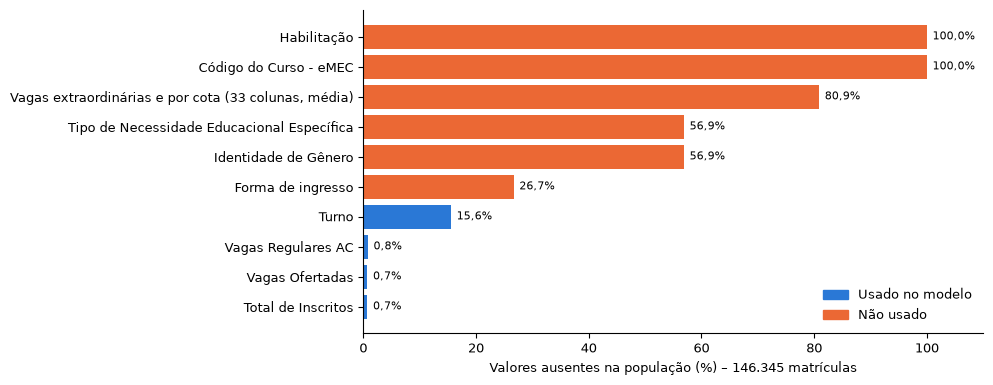

In [8]:
ausentes = dados.isna().mean().mul(100)
ausentes = ausentes[ausentes > 0]
cota = ausentes.index.str.match(r'Vagas (Extraordinárias|Regulares (?!AC$))')
linhas = [(coluna, valor, coluna in ATRIBUTOS) for coluna, valor in ausentes[~cota].items()]
linhas.append((f'Vagas extraordinárias e por cota ({cota.sum()} colunas, média)', ausentes[cota].mean(), False))
linhas = sorted(linhas, key=lambda linha: linha[1])

fig, ax = plt.subplots(figsize=(8, 0.32 * len(linhas) + 1))
ax.barh([l[0] for l in linhas], [l[1] for l in linhas], color=[AZUL if l[2] else LARANJA for l in linhas])
for i, (_, valor, _) in enumerate(linhas):
    ax.text(valor + 1, i, f'{valor:.1f}%'.replace('.', ','), va='center', fontsize=8)
total = f'{len(dados):,}'.replace(',', '.')
ax.set(xlim=(0, 110), xlabel=f'Valores ausentes na população (%) – {total} matrículas')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=LARANJA)],
          labels=['Usado no modelo', 'Não usado'], loc='lower right', frameon=False)
salvar_figura(fig, 'fig_ausencias.png')

### 4.3 Campos do estudante que ficam de fora

Forma de ingresso, identidade de gênero, tipo de NEE, renda familiar e cor/raça existem no cadastro, mas estão
**vazios ou "Não declarada" com muito mais frequência entre os evadidos**, mesmo comparando colegas da mesma turma
(última coluna). A explicação provável é que esses campos foram completados durante o curso, alcançando só quem
continuou matriculado. Se entrassem no modelo, ele aprenderia que "campo vazio indica evasão", um sinal que não existe
para um ingressante com o cadastro completo. Por isso ficam de fora. Eles voltam a ser candidatos quando houver dados
históricos preenchidos já no ingresso.

Os atributos do estudante que ficam no modelo (sexo, tipo de deficiência e idade) não têm esse problema.

In [9]:
nao_informado = pd.DataFrame({
    'Forma de ingresso': dados['Forma de ingresso'].isna(),
    'Identidade de Gênero': dados['Identidade de Gênero'].isna(),
    'Tipo de NEE': dados['Tipo de Necessidade Educacional Específica'].isna(),
    'Renda Familiar': dados['Renda Familiar'].eq('Não declarada'),
    'Cor / Raça': dados['Cor / Raça'].eq('Não declarada'),
})
cadastro_completo = ~nao_informado.any(axis=1)


def diferenca_na_turma(marcado):
    # média, entre as turmas, de (% entre os evadidos − % entre os concluintes) da mesma turma
    por_turma = marcado.groupby([turmas, y]).mean().unstack().dropna()
    return 100 * (por_turma[1] - por_turma[0]).mean()


tabela_nao_informado = (nao_informado.groupby(y).mean().mul(100).T
                        .rename(columns={0: 'concluintes (%)', 1: 'evadidos (%)'}))
tabela_nao_informado['diferença na mesma turma (p.p.)'] = [diferenca_na_turma(nao_informado[c]) for c in nao_informado]
tabela_nao_informado = tabela_nao_informado.round(1)
salvar_tabela(tabela_nao_informado, 'campos_nao_informados_por_desfecho.csv')
print(f'Matrículas com os cinco campos informados: {100 * cadastro_completo.mean():.1f}%'.replace('.', ','))
tabela_nao_informado

Matrículas com os cinco campos informados: 30,3%


Categoria da Situação,concluintes (%),evadidos (%),diferença na mesma turma (p.p.)
Forma de ingresso,11.7,44.1,38.3
Identidade de Gênero,48.0,67.2,26.4
Tipo de NEE,48.0,67.2,26.4
Renda Familiar,18.6,31.2,10.5
Cor / Raça,9.3,15.5,3.0


## 5. Treino, validação e teste

A divisão é feita **por turma** (ciclo de matrícula): 70% das turmas vão para o treino, 15% para a validação e 15%
para o teste. Colegas de turma compartilham curso, unidade, datas e boa parte do destino; se fossem divididos entre
treino e teste, o modelo seria avaliado em turmas que já "conhece" e o resultado ficaria otimista. Assim, o teste
simula o uso real: **turmas novas** de unidades e cursos que já existiam.

- **Treino:** ajusta o modelo.
- **Validação:** decide quando parar o treinamento.
- **Teste:** usado uma única vez, para a avaliação final.

In [10]:
treino, resto = next(GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEMENTE).split(X, y, turmas))
validacao, teste = next(GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEMENTE)
                        .split(X.iloc[resto], y.iloc[resto], turmas.iloc[resto]))
validacao, teste = resto[validacao], resto[teste]
PARTICOES = {'Treino': treino, 'Validação': validacao, 'Teste': teste}
assert set(turmas.iloc[treino]).isdisjoint(turmas.iloc[teste]), 'turma em mais de uma partição'

particoes = pd.DataFrame({nome: {'matrículas': len(i), 'turmas': turmas.iloc[i].nunique(),
                                 'evadidos (%)': round(100 * y.iloc[i].mean(), 1)}
                          for nome, i in PARTICOES.items()}).T.astype({'matrículas': int, 'turmas': int})
salvar_tabela(particoes, 'particoes.csv')
particoes

,matrículas,turmas,evadidos (%)
Treino,102950,2882,46.8
Validação,22080,618,46.5
Teste,21315,618,43.4


## 6. Treinamento do modelo (CatBoost)

O **CatBoost** é um algoritmo de árvores de decisão em sequência (*gradient boosting*), em que cada árvore corrige os
erros das anteriores. Ele foi escolhido porque trata diretamente atributos categóricos com muitos valores, como
curso e unidade de ensino, e valores ausentes.

Os hiperparâmetros são fixos (sem busca), para não ajustar o modelo ao teste. `auto_class_weights='Balanced'` dá o
mesmo peso total a evadidos e concluintes. O treinamento para quando a perda na validação deixa de melhorar por 50
iterações.

0:	learn: 0.6840668	test: 0.6842895	best: 0.6842895 (0)	total: 303ms	remaining: 4m 1s


100:	learn: 0.5682968	test: 0.5856373	best: 0.5856373 (100)	total: 16.2s	remaining: 1m 51s


200:	learn: 0.5611885	test: 0.5822592	best: 0.5822577 (198)	total: 32.3s	remaining: 1m 36s


300:	learn: 0.5570602	test: 0.5817737	best: 0.5814269 (261)	total: 47.9s	remaining: 1m 19s


Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.5814268948
bestIteration = 261

Shrink model to first 262 iterations.
Árvores no modelo final: 262


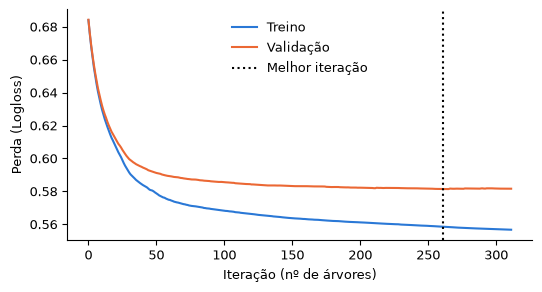

In [11]:
modelo = CatBoostClassifier(**PARAMETROS_CATBOOST, verbose=100, allow_writing_files=False)
modelo.fit(Pool(X.iloc[treino], y.iloc[treino], cat_features=CATEGORICAS),
           eval_set=Pool(X.iloc[validacao], y.iloc[validacao], cat_features=CATEGORICAS),
           early_stopping_rounds=50, use_best_model=True)
print(f'Árvores no modelo final: {modelo.tree_count_}')

curvas = modelo.get_evals_result()
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(curvas['learn']['Logloss'], color=AZUL, label='Treino')
ax.plot(curvas['validation']['Logloss'], color=LARANJA, label='Validação')
ax.axvline(modelo.best_iteration_, ls=':', color='k', label='Melhor iteração')
ax.set(xlabel='Iteração (nº de árvores)', ylabel='Perda (Logloss)')
ax.legend(frameon=False)
salvar_figura(fig, 'fig_curva_aprendizado.png')

## 7. Avaliação

### 7.1 Métricas no teste

- **ROC-AUC:** chance de um evadido sorteado receber escore maior que um concluinte sorteado (0,5 = acaso; 1 = perfeito).
- **Precisão média (AP):** resume a precisão ao longo de todos os pontos de corte; o acaso vale a proporção de evadidos.
- **Acurácia, precisão, revocação e F1:** consideram "alerta" o escore ≥ 0,50.

In [12]:
def metricas(rotulo, escore):
    alerta = (np.asarray(escore) >= LIMIAR).astype(int)
    return {'ROC-AUC': roc_auc_score(rotulo, escore), 'AP': average_precision_score(rotulo, escore),
            'acurácia': accuracy_score(rotulo, alerta), 'precisão': precision_score(rotulo, alerta),
            'revocação': recall_score(rotulo, alerta), 'F1': f1_score(rotulo, alerta)}


escore = modelo.predict_proba(X)[:, 1]
y_teste, escore_teste = y.iloc[teste], escore[teste]
tabela_metricas = pd.DataFrame({nome: metricas(y.iloc[i], escore[i]) for nome, i in PARTICOES.items()}).T
salvar_tabela(tabela_metricas.round(4), 'metricas.csv')
display(tabela_metricas.round(3))

matriz = pd.DataFrame(confusion_matrix(y_teste, (escore_teste >= LIMIAR).astype(int)),
                      index=['Concluiu', 'Evadiu'], columns=['Sem alerta', 'Com alerta'])
salvar_tabela(matriz, 'matriz_confusao_teste.csv')
matriz

,ROC-AUC,AP,acurácia,precisão,revocação,F1
Treino,0.798,0.768,0.722,0.679,0.770,0.722
Validação,0.764,0.722,0.697,0.651,0.756,0.699
Teste,0.767,0.710,0.709,0.652,0.704,0.677


,Sem alerta,Com alerta
Concluiu,8579,3475
Evadiu,2738,6523


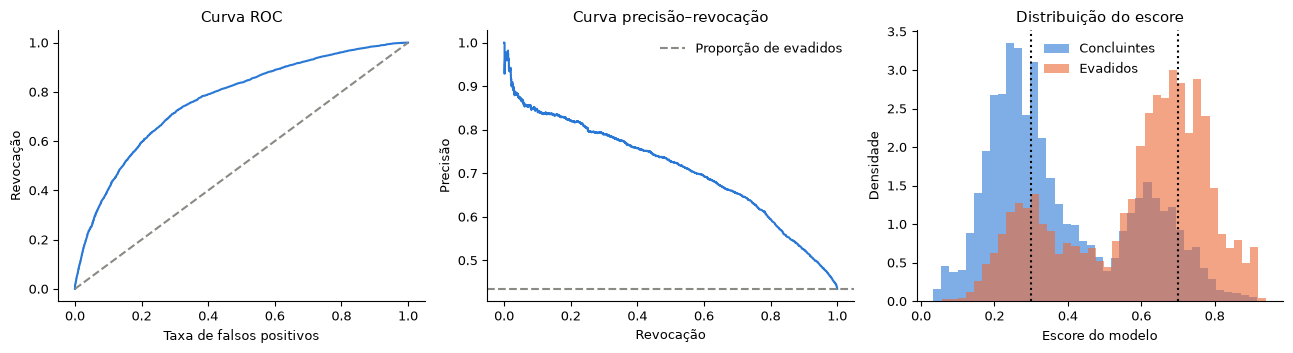

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
fpr, tpr, _ = roc_curve(y_teste, escore_teste)
ax[0].plot(fpr, tpr, color=AZUL)
ax[0].plot([0, 1], [0, 1], '--', color=CINZA)
ax[0].set(title='Curva ROC', xlabel='Taxa de falsos positivos', ylabel='Revocação')
precisao, revocacao, _ = precision_recall_curve(y_teste, escore_teste)
ax[1].plot(revocacao, precisao, color=AZUL)
ax[1].axhline(y_teste.mean(), ls='--', color=CINZA, label='Proporção de evadidos')
ax[1].set(title='Curva precisão–revocação', xlabel='Revocação', ylabel='Precisão')
ax[1].legend(frameon=False)
for classe, cor, nome in ((0, AZUL, 'Concluintes'), (1, LARANJA, 'Evadidos')):
    ax[2].hist(escore_teste[y_teste.to_numpy() == classe], bins=40, alpha=0.6, color=cor, label=nome, density=True)
for limiar in NIVEIS_ALERTA.values():
    ax[2].axvline(limiar, ls=':', color='k')
ax[2].set(title='Distribuição do escore', xlabel='Escore do modelo', ylabel='Densidade')
ax[2].legend(frameon=False)
plt.tight_layout()
salvar_figura(fig, 'fig_roc_pr_escore.png')

### 7.2 Comparação com referências simples

Para saber se o modelo acrescenta algo, ele é comparado, nas mesmas turmas de teste, com alternativas cada vez mais
elaboradas:

1. **Sem modelo:** todos recebem o mesmo escore (a proporção de evadidos do treino). É o ponto de partida (ROC-AUC 0,5).
2. **Regra simples:** cada matrícula recebe a taxa de evasão do seu **tipo de oferta** (integrado, subsequente,
   concomitante, PROEJA…) no treino. É uma regra que a equipe pode aplicar sem nenhum modelo.
3. **Regressão logística:** modelo estatístico clássico e de fácil interpretação, com os mesmos 21 atributos.
4. **CatBoost:** o modelo final.

Além do ROC-AUC no teste inteiro, a tabela mostra o ROC-AUC **dentro de cada unidade de ensino** (média ponderada
pelo número de matrículas, em unidades com ao menos 30 matrículas de teste e as duas classes). Essa é a medida que
importa para o protótipo: uma equipe local compara os seus próprios estudantes, e não unidades entre si.

In [14]:
def auc_dentro_da_unidade(escores, indices, minimo=30):
    tabela = pd.DataFrame({'unidade': X['Unidade de Ensino'].iloc[indices].to_numpy(),
                           'y': y.iloc[indices].to_numpy(), 'escore': escores})
    por_unidade = [(len(g), roc_auc_score(g['y'], g['escore'])) for _, g in tabela.groupby('unidade')
                   if len(g) >= minimo and g['y'].nunique() == 2]
    return np.average([auc for _, auc in por_unidade], weights=[n for n, _ in por_unidade]), len(por_unidade)


taxa_por_oferta = y.iloc[treino].groupby(X['Tipo de Oferta'].iloc[treino]).mean()
regressao_logistica = make_pipeline(
    ColumnTransformer([('categoricos', OneHotEncoder(handle_unknown='ignore', min_frequency=20), CATEGORICAS),
                       ('numericos', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUMERICAS)]),
    LogisticRegression(max_iter=2000, class_weight='balanced'))
regressao_logistica.fit(X.iloc[treino], y.iloc[treino])

ESCORES_TESTE = {
    '1. Sem modelo': np.full(len(teste), y.iloc[treino].mean()),
    '2. Regra simples (taxa do tipo de oferta)': X['Tipo de Oferta'].iloc[teste].map(taxa_por_oferta)
                                                  .fillna(y.iloc[treino].mean()).to_numpy(),
    '3. Regressão logística': regressao_logistica.predict_proba(X.iloc[teste])[:, 1],
    '4. CatBoost (modelo final)': escore_teste,
}
comparacao = pd.DataFrame({nome: {'ROC-AUC': roc_auc_score(y_teste, p), 'AP': average_precision_score(y_teste, p),
                                  'ROC-AUC dentro da unidade': auc_dentro_da_unidade(p, teste)[0]}
                           for nome, p in ESCORES_TESTE.items()}).T
salvar_tabela(comparacao.round(4), 'comparacao_modelos.csv')
comparacao.round(3)

,ROC-AUC,AP,ROC-AUC dentro da unidade
1. Sem modelo,0.500,0.434,0.500
2. Regra simples (taxa do tipo de oferta),0.680,0.562,0.555
3. Regressão logística,0.739,0.679,0.585
4. CatBoost (modelo final),0.767,0.710,0.641


### 7.3 Uso dentro da unidade

O ROC-AUC dentro da unidade responde à pergunta do protótipo: *entre os estudantes desta unidade, o modelo coloca
os que evadiram à frente dos que concluíram?* A segunda linha repete a medida só nas matrículas com o **cadastro
completo** (os cinco campos da seção 4.3 informados), que é a situação esperada para os ingressantes atuais. Valores
próximos indicam que o modelo não depende de o cadastro estar completo.

In [15]:
completo_teste = cadastro_completo.iloc[teste].to_numpy()
auc_unidade, n_unidades = auc_dentro_da_unidade(escore_teste, teste)
auc_unidade_completo, n_unidades_completo = auc_dentro_da_unidade(escore_teste[completo_teste], teste[completo_teste])
uso_na_unidade = pd.DataFrame({
    'Todas as matrículas de teste': {
        'matrículas': len(teste), 'evadidos (%)': 100 * y_teste.mean(), 'unidades avaliadas': n_unidades,
        'ROC-AUC (teste inteiro)': roc_auc_score(y_teste, escore_teste), 'ROC-AUC dentro da unidade': auc_unidade},
    'Só cadastro completo': {
        'matrículas': completo_teste.sum(), 'evadidos (%)': 100 * y_teste[completo_teste].mean(),
        'unidades avaliadas': n_unidades_completo,
        'ROC-AUC (teste inteiro)': roc_auc_score(y_teste[completo_teste], escore_teste[completo_teste]),
        'ROC-AUC dentro da unidade': auc_unidade_completo},
}).T.astype({'matrículas': int, 'unidades avaliadas': int})
salvar_tabela(uso_na_unidade.round(4), 'uso_na_unidade.csv')
uso_na_unidade.round(3)

,matrículas,evadidos (%),unidades avaliadas,ROC-AUC (teste inteiro),ROC-AUC dentro da unidade
Todas as matrículas de teste,21315,43.448,282,0.767,0.641
Só cadastro completo,6417,24.669,66,0.795,0.700


### 7.4 Desempenho por grupo de estudantes

O modelo não usa cor/raça nem renda, mas ainda pode errar mais em alguns grupos. Por isso vale verificar se ele
erra de forma parecida entre eles. A tabela mostra,
para cada grupo com ao menos 200 matrículas de teste: o ROC-AUC, a proporção de evadidos que recebeu alerta
(revocação) e a de concluintes que recebeu alerta sem necessidade (falsos positivos). É uma descrição: diferenças
grandes indicam onde uma avaliação de equidade mais cuidadosa seria necessária antes de um uso real.

In [16]:
alerta_teste = escore_teste >= LIMIAR
linhas = []
for atributo in ('Sexo', 'Cor / Raça', 'Renda Familiar'):
    grupos = dados[atributo].fillna('Desconhecido').iloc[teste].to_numpy()
    for grupo in sorted(set(grupos)):
        m = grupos == grupo
        if m.sum() < 200:
            continue
        evadiu = y_teste.to_numpy()[m] == 1
        linhas.append({'atributo': atributo, 'grupo': grupo, 'matrículas': int(m.sum()),
                       'evadidos (%)': 100 * evadiu.mean(), 'ROC-AUC': roc_auc_score(evadiu, escore_teste[m]),
                       'revocação': alerta_teste[m][evadiu].mean(),
                       'falsos positivos': alerta_teste[m][~evadiu].mean()})
por_grupo = pd.DataFrame(linhas).set_index(['atributo', 'grupo'])
salvar_tabela(por_grupo.round(3), 'desempenho_por_grupo.csv')
por_grupo.round(3)

matrículas  evadidos (%)  ROC-AUC  revocação  falsos positivos
atributo       grupo                                                                        
Sexo           F                   11431        39.892    0.770      0.689             0.269
               M                    9884        47.562    0.758      0.719             0.314
Cor / Raça     Amarela               215        46.512    0.761      0.710             0.313
               Branca               7034        38.854    0.774      0.698             0.259
               Não declarada        2113        58.684    0.716      0.681             0.401
               Parda                9703        42.595    0.766      0.694             0.274
               Preta                2181        47.043    0.770      0.794             0.375
Renda Familiar 0,5<RFP<=1           4148        38.163    0.788      0.742             0.264
               0<RFP<=0,5           6590        39.014    0.747      0.655             0.260
               1,5<RFP<=2,5         1551        39.201    0.793      0.747             0.267
               1<RFP<=1,5           2562        41.725    0.778      0.734             0.317
               2,5<RFP<=3,5          536        34.328    0.771      0.728             0.293
               Não declarada        5192        57.858    0.740      0.705             0.371
               RFP>3,5               736        32.880    0.804      0.719             0.229

## 8. Explicabilidade com SHAP

Para cada matrícula, os valores **SHAP** dividem o escore entre os atributos: quanto cada um empurrou o escore para
cima (mais parecido com evasão) ou para baixo. O valor-base mais a soma das contribuições reproduz exatamente a saída
do modelo. O CatBoost calcula esses valores diretamente.

### 8.1 Importância global
Média do valor absoluto das contribuições em 5.000 matrículas de teste sorteadas.

Participação de cada grupo na importância total (%): {'Curso e oferta': 42.8, 'Estudante': 33.2, 'Instituição': 24.1}


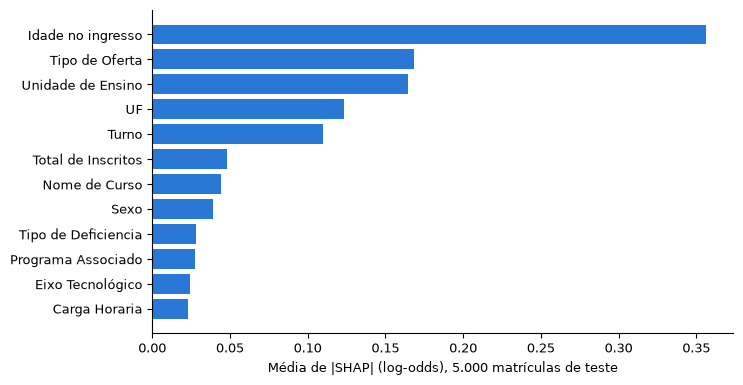

In [17]:
X_teste = X.iloc[teste]
amostra_shap = X_teste.sample(n=5000, random_state=SEMENTE)
shap = modelo.get_feature_importance(Pool(amostra_shap, cat_features=CATEGORICAS), type='ShapValues')
saida_bruta = modelo.predict(amostra_shap, prediction_type='RawFormulaVal')
assert np.allclose(shap.sum(axis=1), saida_bruta), 'valor-base + contribuições deveria reproduzir a saída'

NOMES = {'Idade_Inicio_Estimada': 'Idade no ingresso', 'Duracao_Ciclo_Dias': 'Duração prevista do ciclo'}
importancia = pd.Series(np.abs(shap[:, :-1]).mean(axis=0), index=ATRIBUTOS).sort_values(ascending=False)
grupo = lambda c: ('Estudante' if c in ATRIBUTOS_ESTUDANTE + ['Idade_Inicio_Estimada'] else
                   'Instituição' if c in ATRIBUTOS_INSTITUICAO else 'Curso e oferta')
participacao_grupos = importancia.groupby(grupo).sum().div(importancia.sum()).mul(100).round(1)
salvar_tabela(importancia.round(4).rename('média |SHAP|').to_frame(), 'shap_importancia_global.csv')
print('Participação de cada grupo na importância total (%):', participacao_grupos.to_dict())

principais = importancia.head(12).rename(index=lambda c: NOMES.get(c, c))[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(principais.index, principais.values, color=AZUL)
ax.set_xlabel('Média de |SHAP| (log-odds), 5.000 matrículas de teste')
salvar_figura(fig, 'fig_shap_global.png')

### 8.2 Explicação de uma matrícula
É a mesma explicação que o protótipo mostra para cada estudante: os atributos que mais elevaram (laranja) ou
reduziram (azul) o escore.

Escore do modelo: 0.431


,valor,contribuição
Idade_Inicio_Estimada,17.2,0.235
Unidade de Ensino,Campus São João do Piauí,-0.219
Tipo de Oferta,Integrado,-0.147
Turno,Matutino,-0.110
UF,PI,-0.066
Nome de Curso,Técnico em Agropecuária,0.047
Sexo,F,-0.041
Eixo Tecnológico,Recursos Naturais,0.027


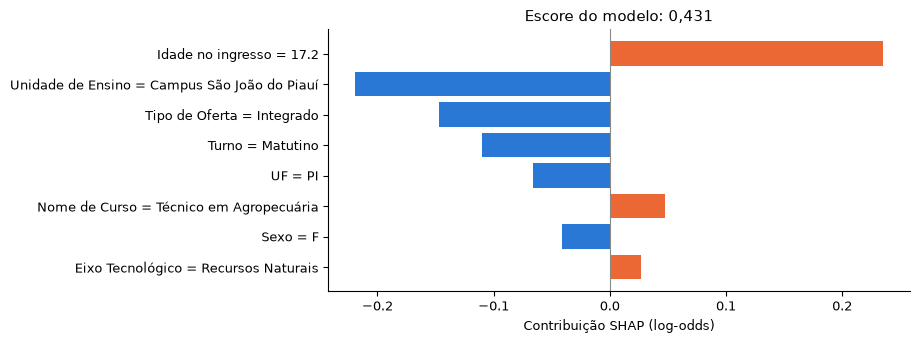

In [18]:
exemplo = shap[0]
valor_base, contribuicoes = exemplo[-1], exemplo[:-1]
escore_exemplo = 1 / (1 + np.exp(-(valor_base + contribuicoes.sum())))
explicacao = (pd.DataFrame({'valor': amostra_shap.iloc[0].astype(str), 'contribuição': contribuicoes}, index=ATRIBUTOS)
              .sort_values('contribuição', key=abs, ascending=False).head(8))
print(f'Escore do modelo: {escore_exemplo:.3f}')
display(explicacao.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
explicacao = explicacao[::-1]
ax.barh([f'{NOMES.get(c, c)} = {v}' for c, v in explicacao['valor'].items()], explicacao['contribuição'],
        color=np.where(explicacao['contribuição'] >= 0, LARANJA, AZUL))
ax.axvline(0, color=CINZA, linewidth=0.8)
ax.set(xlabel='Contribuição SHAP (log-odds)', title=f'Escore do modelo: {escore_exemplo:.3f}'.replace('.', ','))
salvar_figura(fig, 'fig_shap_exemplo.png')

## 9. Níveis de alerta

O protótipo agrupa os escores em três níveis: **Baixo** (< 0,30), **Médio** (0,30 a 0,70) e **Alto** (≥ 0,70). Os
pontos de corte são experimentais, escolhidos para facilitar a leitura, e não foram otimizados. A tabela mostra que,
no teste, a evasão observada cresce de um nível para o outro.

In [19]:
def nivel_alerta(escores):
    return np.select([escores < NIVEIS_ALERTA['medio'], escores < NIVEIS_ALERTA['alto']], ['Baixo', 'Médio'], 'Alto')


niveis = (pd.DataFrame({'nível': nivel_alerta(escore_teste), 'evadiu': y_teste.to_numpy()})
          .groupby('nível')['evadiu'].agg(matrículas='size', evasao_observada_pct=lambda s: 100 * s.mean())
          .reindex(['Baixo', 'Médio', 'Alto']))
niveis['participação (%)'] = 100 * niveis['matrículas'] / niveis['matrículas'].sum()
salvar_tabela(niveis.round(1), 'niveis_alerta_teste.csv')
niveis.round(1)

,matrículas,evasao_observada_pct,participação (%)
nível,,,
Baixo,6682,18.9,31.3
Médio,10651,45.9,50.0
Alto,3982,78.0,18.7


## 10. Exportação para o protótipo

Os arquivos vão para `resultados/prototipo/`, no formato lido pelo protótipo. A base de demonstração vem só do
**teste**, sem desfecho e sem códigos de matrícula:
- `base_demonstracao.csv`: as 3 maiores unidades de uma instituição por região do país. Para reduzir o risco de
  identificação, são retiradas as combinações de unidade, curso, sexo e tipo de deficiência com menos de 5 pessoas;
- `particao_ciclos_2025.csv`: em que partição ficou cada turma, para o protótipo avisar quando uma turma foi usada
  no treino;
- `resultados_modelo.json` (seção 11): os números da avaliação, mostrados na página técnica do protótipo.

In [20]:
PASTA_PROTOTIPO = SAIDA / 'prototipo'


def exportar_csv(tabela, nome):
    tabela.rename(columns={'Idade_Inicio_Estimada': 'Idade no ingresso'}).to_csv(
        PASTA_PROTOTIPO / nome, index=False, encoding='utf-8-sig')


# Base com várias instituições: a instituição com mais matrículas de teste em cada região, com 3 unidades
REGIAO = {uf: regiao for regiao, ufs in {'Norte': 'AC AM AP PA RO RR TO', 'Nordeste': 'AL BA CE MA PB PE PI RN SE',
                                         'Centro-Oeste': 'DF GO MS MT', 'Sudeste': 'ES MG RJ SP',
                                         'Sul': 'PR RS SC'}.items() for uf in ufs.split()}
por_unidade = (X_teste.groupby(['Instituição', 'Unidade de Ensino'])
               .agg(matriculas=('UF', 'size'), cursos=('Nome de Curso', 'nunique'), uf=('UF', 'first')).reset_index())
por_unidade = por_unidade[por_unidade['matriculas'].ge(50) & por_unidade['cursos'].ge(2)]
tres_maiores = (por_unidade.sort_values('matriculas', ascending=False, kind='stable')
                .groupby('Instituição').head(3).groupby('Instituição').filter(lambda g: len(g) == 3))
tres_maiores = tres_maiores.assign(regiao=tres_maiores['uf'].map(REGIAO))
instituicoes = (tres_maiores.groupby(['regiao', 'Instituição'])['matriculas'].sum().reset_index()
                .sort_values('matriculas', ascending=False, kind='stable').groupby('regiao').head(1))
escolhidas = tres_maiores[tres_maiores['Instituição'].isin(instituicoes['Instituição'])]
chave_unidade = X_teste['Instituição'] + '|' + X_teste['Unidade de Ensino']
demo = X_teste[chave_unidade.isin(escolhidas['Instituição'] + '|' + escolhidas['Unidade de Ensino'])]
combinacao = ['Instituição', 'Unidade de Ensino', 'Nome de Curso', 'Sexo', 'Tipo de Deficiencia']
tamanho = demo.groupby(combinacao)['UF'].transform('size')
demo = demo[tamanho >= 5].sort_values(['Instituição', 'Unidade de Ensino'], kind='stable')
exportar_csv(demo, 'base_demonstracao.csv')
print(f'Base de demonstração: {len(demo)} matrículas de {len(escolhidas)} unidades '
      f'({", ".join(sorted(instituicoes["Instituição"]))}); {int((tamanho < 5).sum())} retiradas pela regra dos 5')

# Turma → partição
mapa = pd.concat([pd.DataFrame({'Código do Ciclo Matricula': turmas.iloc[i].unique(), 'particao': nome})
                  for nome, i in PARTICOES.items()]).sort_values('Código do Ciclo Matricula')
mapa.to_csv(PASTA_PROTOTIPO / 'particao_ciclos_2025.csv', index=False, encoding='utf-8-sig')

Base de demonstração: 1829 matrículas de 15 unidades (IFCE, IFES, IFMT, IFPA, IFSUL); 35 retiradas pela regra dos 5


O modelo é gravado com um esquema que lista os atributos na ordem esperada. Em seguida, ele é recarregado para
confirmar que reproduz os mesmos escores.

In [21]:
modelo.save_model(str(PASTA_PROTOTIPO / 'modelo_evasao.cbm'))
esquema = {
    'colunas': ATRIBUTOS, 'categoricas': CATEGORICAS, 'numericas': NUMERICAS,
    'grupos': {'estudante': ATRIBUTOS_ESTUDANTE + ['Idade_Inicio_Estimada'], 'instituicao': ATRIBUTOS_INSTITUICAO},
    'limiares': NIVEIS_ALERTA, 'ref_idade': str(REFERENCIA_IDADE.date()),
    'modelo': f'CatBoost, cursos técnicos, {len(ATRIBUTOS)} atributos disponíveis no ingresso',
    'fonte': 'Microdados de Eficiência Acadêmica da PNP, ano-base 2025',
    'observacao': 'Escore não calibrado; níveis experimentais; avaliação retrospectiva.',
}
with open(PASTA_PROTOTIPO / 'esquema_modelo.json', 'w', encoding='utf-8') as arquivo:
    json.dump(esquema, arquivo, ensure_ascii=False, indent=2)

recarregado = CatBoostClassifier().load_model(str(PASTA_PROTOTIPO / 'modelo_evasao.cbm'))
assert list(recarregado.feature_names_) == ATRIBUTOS
assert np.array_equal(recarregado.predict_proba(X_teste)[:, 1], escore_teste)
print('Modelo recarregado reproduz os escores do teste.')

Modelo recarregado reproduz os escores do teste.


## 11. Resumo dos resultados

Os principais números ficam em `resultados/resultados.json`, com cópia em `resultados/prototipo/resultados_modelo.json`.
No Colab, a pasta `resultados/` é compactada e oferecida para download.

In [22]:
RESULTADOS = {
    'dados': {'arquivo': ARQUIVO_DADOS.name, 'sha256': SHA256_DADOS},
    'populacao': {'matriculas': len(dados), 'turmas': int(turmas.nunique()), 'evasao_pct': round(100 * y.mean(), 2)},
    'particoes': particoes.to_dict(orient='index'),
    'modelo': {'arvores': int(modelo.tree_count_), 'atributos': len(ATRIBUTOS), 'parametros': PARAMETROS_CATBOOST},
    'metricas': tabela_metricas.round(4).to_dict(orient='index'),
    'matriz_confusao_teste': matriz.to_dict(),
    'comparacao_modelos': comparacao.round(4).to_dict(orient='index'),
    'uso_na_unidade': uso_na_unidade.round(4).to_dict(orient='index'),
    'campos_nao_informados_pct': tabela_nao_informado.to_dict(orient='index'),
    'shap_participacao_grupos_pct': participacao_grupos.to_dict(),
    'niveis_teste': niveis.round(1).to_dict(orient='index'),
    'ambiente': {'python': platform.python_version(), 'catboost': catboost.__version__, 'pandas': pd.__version__,
                 'scikit-learn': sklearn.__version__},
}
for destino in (SAIDA / 'resultados.json', PASTA_PROTOTIPO / 'resultados_modelo.json'):   # cópia para o protótipo
    with open(destino, 'w', encoding='utf-8') as arquivo:
        json.dump(RESULTADOS, arquivo, ensure_ascii=False, indent=2, default=lambda v: v.item())

resumo = pd.Series({
    'Matrículas na população': f'{len(dados):,}'.replace(',', '.'),
    'Evadidos': f'{100 * y.mean():.1f}%',
    'ROC-AUC no teste': f'{comparacao.loc["4. CatBoost (modelo final)", "ROC-AUC"]:.3f}',
    'ROC-AUC dentro da unidade': f'{auc_unidade:.3f}',
    'ROC-AUC dentro da unidade, cadastro completo': f'{auc_unidade_completo:.3f}',
    'Ganho sobre a regressão logística (ROC-AUC)':
        f'{comparacao["ROC-AUC"].iloc[3] - comparacao["ROC-AUC"].iloc[2]:+.3f}',
}, name='valor')
display(resumo.to_frame())

if 'google.colab' in sys.modules:
    import shutil
    from google.colab import files
    files.download(shutil.make_archive('resultados', 'zip', '.', 'resultados'))

,valor
Matrículas na população,146.345
Evadidos,46.3%
ROC-AUC no teste,0.767
ROC-AUC dentro da unidade,0.641
"ROC-AUC dentro da unidade, cadastro completo",0.700
Ganho sobre a regressão logística (ROC-AUC),+0.027
